Ejemplos de uso de pycliques
============================



## Cargar bibliotecas



In [7]:
# @title Environment Setup
%%capture
!pip install "git+https://github.com/rvf0068/pycliques-project.git#subdirectory=packages/pycombtop" "git+https://github.com/rvf0068/pycliques-project.git#subdirectory=packages/pycliques"

In [9]:
import networkx as nx
from pycliques import *
from pycombtop import *

## Periódicas



Las gráficas bipartitas no tienen triángulos, por lo tanto, son periódicas.



In [10]:
g = nx.complete_bipartite_graph(3, 4)
cs = CliqueSequence(g)
[cs[i].order() for i in range(10)]

[7, 12, 7, 12, 7, 12, 7, 12, 7, 12]

También la gráfica de Petersen es periódica, con período 2.



In [11]:
g = nx.petersen_graph()
cs = CliqueSequence(g)
[cs[i].order() for i in range(10)]

[10, 15, 10, 15, 10, 15, 10, 15, 10, 15]

El producto fuerte de gráficas se comporta bien respecto al operador de clanes. Damos un argumento extra a la función CliqueSequence para admitir gráficas de mayor tamaño.



In [12]:
g = nx.strong_product(nx.complete_bipartite_graph(4, 3),
                      nx.petersen_graph())
cs = CliqueSequence(g, 200)
[cs[i].order() for i in range(10) if cs[i] is not None]

[70, 180, 70, 180, 70, 180, 70, 180, 70, 180]

## Gráficas aleatorias



Veremos un ejemplo de una gráfica aleatoria. Aquí fijamos la semilla para no tener sorpresas.



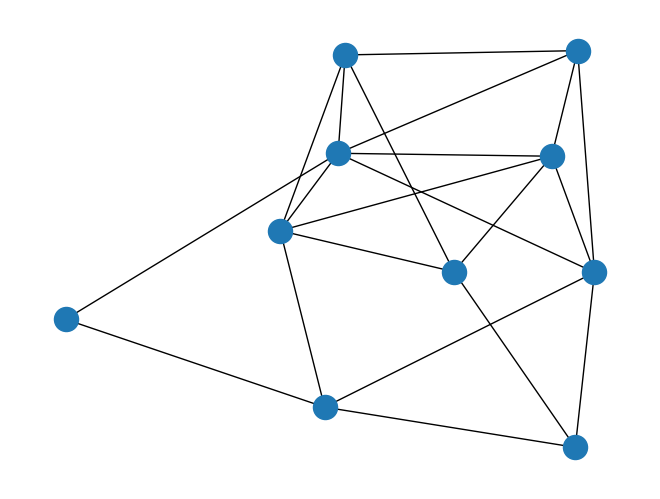

In [13]:
g = nx.gnp_random_graph(10, 0.5, 300)
nx.draw(g)

In [14]:
cs = CliqueSequence(g)
[cs[i].order() for i in range(10)]

[10, 8, 8, 8, 8, 8, 8, 8, 8, 8]

La siguiente gráfica aleatoria es nueva.



In [26]:
g = nx.gnp_random_graph(15, 0.7)
cs = CliqueSequence(g, 50)
[cs[i].order() for i in range(10) if cs[i] is not None]

[15, 17, 42]

In [27]:
behavior = classify_clique_behavior(g)
{
    "verdict": behavior.verdict.name,
    "reason": behavior.reason,
    "iterations_checked": behavior.iterations_checked,
}

{'verdict': 'DIVERGENT',
 'reason': 'eventually has a special octahedron (index 0, dimension 3)',
 'iterations_checked': 2}

El siguiente procedimiento suele crear gráficas con comportamiento interesante.



In [31]:
g = nx.gnp_random_graph(8, 0.5)
mg = nx.complement(nx.line_graph(g))
cs = CliqueSequence(mg, 200)
[cs[i].order() for i in range(10) if cs[i] is not None]

[16, 44, 94]

In [32]:
behavior = classify_clique_behavior(mg)
{
    "verdict": behavior.verdict.name,
    "reason": behavior.reason,
    "iterations_checked": behavior.iterations_checked,
}

KeyboardInterrupt: 

## Relojes



Los relojes dan ejemplos de gráficas cuya sucesión de iteradas de clanes crece linealmente.



In [33]:
g = clockwork_graph([1, 1, 1], [[1], [0], [0]], 2, [1, 0])
cs = CliqueSequence(g, 60)
[cs[i].order() for i in range(10) if cs[i] is not None]

[9, 11, 13, 15, 17, 19, 21, 23, 25, 27]

Este es otro procedimiento que genera gráficas con comportamiento interesante.



In [34]:
hg = homotopy_clique_graph(g)
cs = CliqueSequence(hg, 100)
[cs[i].order() for i in range(10) if cs[i] is not None]

[34, 34, 38, 46, 54, 64, 80, 98]

## Otras gráficas interesantes



Esta tarda aproximadamente 20 segundos.



In [35]:
g = nx.from_graph6_bytes(b"ICqnfp}\\o")
hg = homotopy_clique_graph(g)
cs = CliqueSequence(hg, 700)
[cs[i].order() for i in range(10) if cs[i] is not None]

[54, 50, 67, 89, 148, 267, 606]